# Mini-Project 2: Solar Micro-Grid Dispatch Planner

**The scenario.** A rural health centre in Kasese runs a micro-grid. Each
day, the energy drawn from solar panels (`x`) and batteries (`y`) has to
satisfy two demand constraints:

$$3x + 2y = D_1 \quad\text{(daytime load, kWh)}$$
$$4x + \phantom{2}y = D_2 \quad\text{(critical-equipment load, kWh)}$$

**What has to be decided.** Whether the system can be trusted at all, how
much energy comes from each source on each of 30 days, what to do about days
that have no physical solution, which source is the more erratic, and what
the whole thing costs.

**Where the code lives.** `src/projects/p2_microgrid.py`. The conditioning
diagnostics, the solvers, the repair strategy and the costing are all
methods on classes there; this notebook runs them and interprets the output.

In [1]:
import sys
import timeit
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import statistics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.core.plotting import DATA_DIR, PALETTE, apply_style, save
from src.projects.p2_microgrid import (
    Conditioning, DemandLog, DispatchStatus, HybridMicroGrid, MicroGrid,
    TariffSchedule, monte_carlo_sensitivity)

apply_style()
SEED = 7
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", "{:,.3f}".format)

grid = MicroGrid()
print(repr(grid))

MicroGrid(order=2, det=-5, cond=5.828, well-conditioned)


## Task 1: is the system well posed?

Two numbers decide whether it is worth solving at all.

* **The determinant** says whether a unique answer exists. Here
  $\det A = 3\times1 - 2\times4 = -5$. It is non-zero, so the two loads are
  linearly independent and every pair $(D_1, D_2)$ has exactly one mix of
  solar and battery behind it. Had it been zero, the second constraint would
  have carried no information the first did not, and there would be either no
  solution or infinitely many.
* **The condition number** says whether that answer can be *believed*. It
  bounds how far a relative error in the demand readings can be amplified in
  the dispatch: a 1% error in $D$ can become at most $\kappa$ percent in the
  solution. Here $\kappa \approx 5.83$, which is small. Metering error will
  not be magnified into nonsense.

In [2]:
pd.Series(grid.diagnose()).to_frame("value")

,value
order,2
determinant,-5.000
condition_number,5.828
rank,2
full_rank,True
verdict,well-conditioned


In [3]:
# Verify the determinant by hand, and show what a dependent system looks like.
assert np.isclose(grid.determinant, 3 * 1 - 2 * 4)
print(f"det A = 3*1 - 2*4 = {grid.determinant:.0f}   [matches by hand]")
print(f"cond  = {grid.condition_number:.4f}  ->  {grid.conditioning}")
print()

dependent = MicroGrid([[1.0, 2.0], [2.0, 4.0]])
print("a system whose second load is just twice the first:")
print(" ", repr(dependent))
try:
    dependent.solve_day(10, 20)
except ValueError as err:
    print("  refused ->", err)

det A = 3*1 - 2*4 = -5   [matches by hand]
cond  = 5.8284  ->  well-conditioned

a system whose second load is just twice the first:
  MicroGrid(order=2, det=0, cond=2.518e+16, singular)
  refused -> refusing to solve a singular system (det=0, cond=2.518e+16)


## Task 2: two ways to get the demand in

### (a) Interactive entry, with validation that re-prompts

`DemandLog.ask` keeps asking until a usable number arrives. It rejects
blanks, non-numeric text, negatives and non-finite values, and says which of
those went wrong. The reader and writer are injected, which is what lets the
notebook demonstrate it without a human at the keyboard -- and lets the test
suite drive it too.

In [4]:
log = DemandLog()

for attempt in ["", "abc", "-5", "nan", "1,250.5"]:
    try:
        print(f"  {attempt!r:<12} -> accepted as {DemandLog.parse(attempt)}")
    except ValueError as err:
        print(f"  {attempt!r:<12} -> rejected: {err}")

print("\na scripted session, standing in for a user at the keyboard:")
typed = iter(["", "ninety", "-40", "104.2"])
value = DemandLog.ask("  D1 (kWh): ", reader=lambda prompt: next(typed), attempts=4)
print(f"  accepted D1 = {value}")

print("\nand one that never gets a usable answer:")
try:
    DemandLog.ask("  D2 (kWh): ", reader=lambda prompt: "still not a number",
                  attempts=2)
except ValueError as err:
    print(f"  gave up -> {err}")

  ''           -> rejected: please enter a number (the entry was blank)
  'abc'        -> rejected: 'abc' is not a number
  '-5'         -> rejected: the demand cannot be negative
  'nan'        -> rejected: the demand must be a finite number
  '1,250.5'    -> accepted as 1250.5

a scripted session, standing in for a user at the keyboard:
  please enter a number (the entry was blank). 3 attempt(s) left.
  'ninety' is not a number. 2 attempt(s) left.
  the demand cannot be negative. 1 attempt(s) left.
  accepted D1 = 104.2

and one that never gets a usable answer:
  'still not a number' is not a number. 1 attempt(s) left.
  'still not a number' is not a number. 0 attempt(s) left.
  gave up -> no valid entry after 2 attempts


### (b) Thirty days from a CSV

The file is generated here rather than supplied, so it has to be realistic:
a weekly rhythm (the health centre is busier on weekdays) multiplied by
noise. Everything goes through `np.random.default_rng(SEED)`, so re-running
the notebook reproduces the same file byte for byte.

In [5]:
csv_path = DATA_DIR / "demand_30days.csv"
demand_frame = log.generate(csv_path, days=30, seed=SEED, base=(100.0, 120.0),
                            weekly_swing=0.12, noise=0.05)
print(f"wrote {csv_path.relative_to(ROOT)}")
demand_frame.head(7)

wrote data\demand_30days.csv


,day,D1,D2
0,1,100.010,110.820
1,2,111.020,128.120
2,3,110.170,127.480
3,4,100.520,121.140
4,5,92.640,119.790
5,6,83.920,101.680
6,7,90.890,108.560


In [6]:
loaded = log.load(csv_path)
demands = log.as_matrix(loaded)
print("demand matrix:", demands.shape, "(loads x days)")
loaded[["D1", "D2"]].describe().loc[["mean", "std", "min", "max"]]

demand matrix: (2, 30) (loads x days)


,D1,D2
mean,98.348,120.250
std,10.362,10.424
min,77.190,99.470
max,113.210,139.800


## Task 3: solving 30 days, in a loop and all at once

Both routes call `scipy.linalg.solve`. The difference is that the loop
factorises the same 2x2 matrix thirty times, while the vectorised call
factorises it once and applies it to a 2x30 right-hand side.

In [7]:
by_loop = grid.solve_sequentially(demands)
at_once = grid.solve(demands)
assert np.allclose(by_loop, at_once)
print("the two routes agree to within floating-point error")

loop_time = timeit.timeit(lambda: grid.solve_sequentially(demands), number=200) / 200
fast_time = timeit.timeit(lambda: grid.solve(demands), number=200) / 200
print(f"\nloop       : {loop_time * 1e6:8.1f} us per call")
print(f"vectorised : {fast_time * 1e6:8.1f} us per call")
print(f"speed-up   : {loop_time / fast_time:8.1f}x")

the two routes agree to within floating-point error



loop       :   1997.9 us per call
vectorised :    320.3 us per call
speed-up   :      6.2x


**Reading the timing.** The speed-up is real but it is not about the
arithmetic. A 2x2 solve is a handful of floating-point operations; thirty of
them is nothing. What the loop pays for is thirty round trips into SciPy --
argument checking, dtype inspection, LAPACK set-up -- and that per-call
overhead dwarfs the work. Vectorising amortises it over the whole batch.
The lesson generalises: when the per-item work is small, batching wins on
overhead rather than on FLOPs.

## Task 4: days that have no physical solution

Solving the system is not the same as finding a usable answer. From
$x = (2D_2 - D_1)/5$ and $y = (4D_1 - 3D_2)/5$, the battery allocation goes
negative whenever $D_2 > \tfrac{4}{3}D_1$. A negative allocation is not a
dispatch: a battery cannot absorb energy to balance the books while the
load is still running.

**The strategy taken here** is the first one the brief offers: clip the
negative component to zero and *report what that fails to deliver*. Clipping
breaks the equality, and the size of the breach,
$\lVert A\hat{s} - d \rVert$, is exactly the energy the micro-grid cannot
supply. Carrying it through to the report means a repaired day is never
presented as though it had been met.

In [8]:
feasibility = pd.DataFrame({
    "D1": demands[0], "D2": demands[1],
    "4/3 x D1": 4 / 3 * demands[0],
    "raw solar": at_once[0], "raw battery": at_once[1],
})
feasibility["infeasible"] = grid.infeasible(at_once)
print(f"{feasibility['infeasible'].sum()} of {len(feasibility)} days are infeasible")
feasibility[feasibility["infeasible"]].round(2)

4 of 30 days are infeasible


,D1,D2,4/3 x D1,raw solar,raw battery,infeasible
16,104.190,139.800,138.920,35.080,-0.530,True
19,82.610,116.560,110.150,30.100,-3.850,True
20,82.270,112.890,109.690,28.700,-1.920,True
26,77.190,105.610,102.920,26.810,-1.610,True


In [9]:
report = grid.dispatch(demands)
print(repr(report))
print(f"\n{report.n_repaired} day(s) repaired, leaving "
      f"{report.total_unmet:,.1f} kWh unmet in total")
report.repaired_days().round(2)

DispatchReport(days=30, repaired=4, unmet=17.7 kWh)

4 day(s) repaired, leaving 17.7 kWh unmet in total


,solar,battery,D1,D2,status,unmet_kwh
day,,,,,,
16,35.080,0.000,104.190,139.800,repaired,1.180
19,30.100,0.000,82.610,116.560,repaired,8.600
20,28.700,0.000,82.270,112.890,repaired,4.290
26,26.810,0.000,77.190,105.610,repaired,3.610


In [10]:
report.table.head(10).round(2)

,solar,battery,D1,D2,status,unmet_kwh
day,,,,,,
0,24.330,13.520,100.010,110.820,met,0.000
1,29.040,11.940,111.020,128.120,met,0.000
2,28.960,11.650,110.170,127.480,met,0.000
3,28.350,7.730,100.520,121.140,met,0.000
4,29.390,2.240,92.640,119.790,met,0.000
5,23.890,6.130,83.920,101.680,met,0.000
6,25.250,7.580,90.890,108.560,met,0.000
7,28.780,10.170,106.700,125.310,met,0.000
8,29.630,8.890,106.690,127.430,met,0.000


## Task 5: which source is the more volatile?

Variance alone cannot answer this. It is measured in kWh-squared and it
scales with the size of the source, so the bigger supplier will usually look
more variable whether or not it is more erratic. The coefficient of variation
-- standard deviation over mean -- is unit-free and makes the comparison fair.

In [11]:
volatility = report.volatility()
volatility

,mean_kwh,variance,stdev,cv
source,,,,
solar,28.430,8.042,2.836,0.100
battery,6.792,21.639,4.652,0.685


In [12]:
solar, battery = volatility.loc["solar"], volatility.loc["battery"]
print(f"solar   : mean {solar['mean_kwh']:6.2f} kWh, sd {solar['stdev']:5.2f}, "
      f"CV {solar['cv']:.3f}")
print(f"battery : mean {battery['mean_kwh']:6.2f} kWh, sd {battery['stdev']:5.2f}, "
      f"CV {battery['cv']:.3f}")
print(f"\nThe battery supplies about {solar['mean_kwh'] / battery['mean_kwh']:.1f}x less")
print(f"energy than the panels but its CV is {battery['cv'] / solar['cv']:.1f}x higher.")
print("It is the swing producer: it absorbs whatever the fixed ratio between")
print("the two loads leaves over, so it carries all of the day-to-day variation.")

solar   : mean  28.43 kWh, sd  2.84, CV 0.100
battery : mean   6.79 kWh, sd  4.65, CV 0.685

The battery supplies about 4.2x less
energy than the panels but its CV is 6.9x higher.
It is the swing producer: it absorbs whatever the fixed ratio between
the two loads leaves over, so it carries all of the day-to-day variation.


## Task 6: what does it cost?

The brief's tariffs: solar UGX 150/kWh, battery UGX 450/kWh. The battery is
three times dearer per unit *and* it is the volatile one, so it drives both
the level and the variability of the bill.

In [13]:
tariff = TariffSchedule()
daily_cost = tariff.daily(report.table)

print(f"mean daily cost   : UGX {daily_cost.mean():>12,.0f}")
print(f"cheapest day      : UGX {daily_cost.min():>12,.0f}")
print(f"dearest day       : UGX {daily_cost.max():>12,.0f}")
print(f"30-day total      : UGX {tariff.total(report.table):>12,.0f}")
print(f"monthly run rate  : UGX {tariff.monthly(report.table):>12,.0f}")

share = pd.Series({
    "solar": report.table["solar"].sum() * tariff.rates["solar"],
    "battery": report.table["battery"].sum() * tariff.rates["battery"],
})
print(f"\nbattery is {share['battery'] / share.sum():.0%} of the bill "
      f"on {report.table['battery'].sum() / report.table[['solar', 'battery']].sum().sum():.0%} "
      f"of the energy")

mean daily cost   : UGX        7,321
cheapest day      : UGX        4,021
dearest day       : UGX       11,918
30-day total      : UGX      219,634
monthly run rate  : UGX      219,634

battery is 42% of the bill on 19% of the energy


## Task 7: daily dispatch and daily cost

saved: mp2_dispatch.png


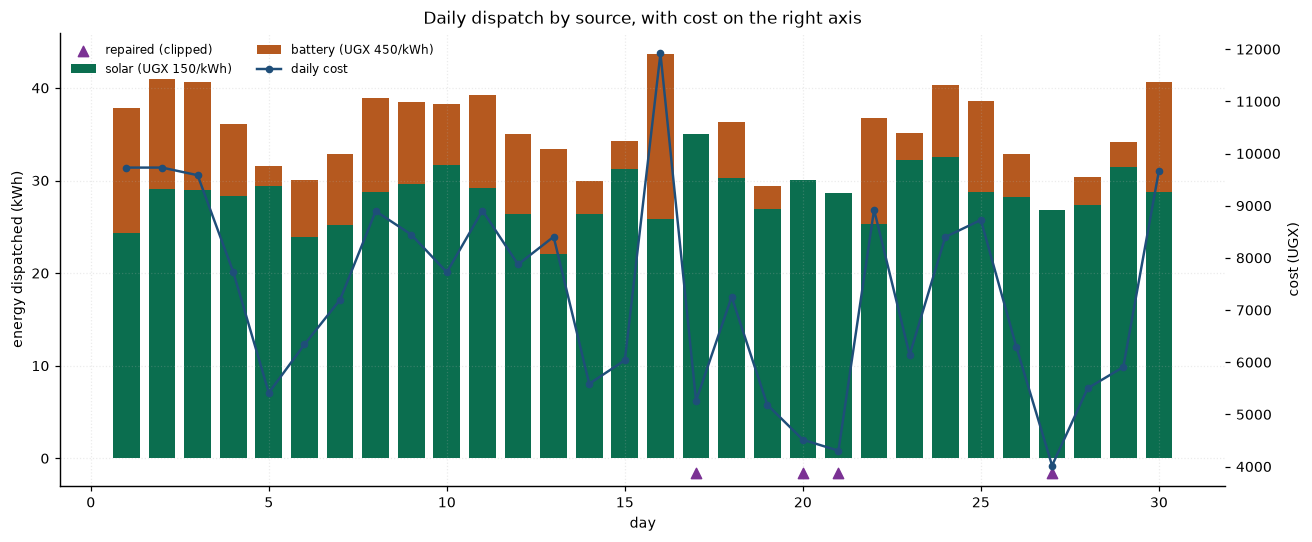

In [14]:
fig, ax = plt.subplots(figsize=(12, 5))
days = report.table.index + 1

ax.bar(days, report.table["solar"], label="solar (UGX 150/kWh)",
       color=PALETTE[0], width=0.75)
ax.bar(days, report.table["battery"], bottom=report.table["solar"],
       label="battery (UGX 450/kWh)", color=PALETTE[1], width=0.75)

repaired = report.table.index[report.flagged] + 1
ax.scatter(repaired, np.full(repaired.size, -1.6), marker="^", s=45,
           color=PALETTE[3], zorder=5, label="repaired (clipped)")

ax.set_xlabel("day")
ax.set_ylabel("energy dispatched (kWh)")
ax.set_ylim(bottom=-3)
ax.set_title("Daily dispatch by source, with cost on the right axis")

cost_axis = ax.twinx()
cost_axis.plot(days, daily_cost, "o-", color=PALETTE[2], ms=4, lw=1.6,
               label="daily cost")
cost_axis.set_ylabel("cost (UGX)")
cost_axis.grid(False)

handles = ax.get_legend_handles_labels()[0] + cost_axis.get_legend_handles_labels()[0]
labels = ax.get_legend_handles_labels()[1] + cost_axis.get_legend_handles_labels()[1]
ax.legend(handles, labels, loc="upper left", fontsize=8, ncol=2)
fig.tight_layout()
print("saved:", save(fig, "mp2_dispatch.png").name)
plt.show()

The repaired days are the ones where the bar is pure solar: the battery
contribution has been clipped to zero, and the cost line dips with it --
which is exactly why cost alone is a misleading summary. Those days look
cheap because demand went unserved.

## Extension 1: a diesel generator and a third constraint

`HybridMicroGrid` subclasses `MicroGrid` and inherits every solver,
diagnostic and repair method unchanged; it supplies only a bigger matrix.
The third constraint chosen here is the **evening load**, served once the
panels have stopped producing:

$$3x + 2y \phantom{{}+ 4z} = D_1 \quad\text{(daytime)}$$
$$4x + \phantom{2}y \phantom{{}+ 4z} = D_2 \quad\text{(critical equipment)}$$
$$2x + 3y + 4z = D_3 \quad\text{(evening load)}$$

The coefficients say a unit of diesel contributes twice what a unit of solar
does after dark, which is the whole reason for installing it.

In [15]:
hybrid = HybridMicroGrid()
print(repr(hybrid))
pd.Series(hybrid.diagnose()).to_frame("value")

HybridMicroGrid(order=3, det=-20, cond=8.176, well-conditioned)


,value
order,3
determinant,-20.000
condition_number,8.176
rank,3
full_rank,True
verdict,well-conditioned


In [16]:
evening = np.round(demands.sum(axis=0) * 0.85, 2)         # illustrative D3
three_load = np.vstack([demands, evening])
hybrid_report = hybrid.dispatch(three_load)
print(repr(hybrid_report))
hybrid_report.table.head(6).round(2)

DispatchReport(days=30, repaired=4, unmet=29.6 kWh)


,solar,battery,diesel,D1,D2,D3,status,unmet_kwh
day,,,,,,,,
0,24.330,13.520,22.500,100.010,110.820,179.210,met,0.000
1,29.040,11.940,27.340,111.020,128.120,203.270,met,0.000
2,28.960,11.650,27.290,110.170,127.480,202.000,met,0.000
3,28.350,7.730,27.130,100.520,121.140,188.410,met,0.000
4,29.390,2.240,28.770,92.640,119.790,180.570,met,0.000
5,23.890,6.130,22.900,83.920,101.680,157.760,met,0.000


In [17]:
hybrid_tariff = TariffSchedule()
print("hybrid volatility:")
print(hybrid_report.volatility().round(3).to_string())
print(f"\n30-day cost with diesel: UGX {hybrid_tariff.total(hybrid_report.table):,.0f}")

hybrid volatility:
         mean_kwh  variance  stdev    cv
source                                  
solar      28.430     8.042  2.836 0.100
battery     6.792    21.639  4.652 0.685
diesel     27.340     9.448  3.074 0.112

30-day cost with diesel: UGX 957,825


### What if the third equation is linearly dependent?

In [18]:
broken = HybridMicroGrid.with_dependent_load()
print("third row replaced by (row 1 + row 2):")
print(broken.A)
print()
print(repr(broken))
try:
    broken.solve_day(100, 120, 220)
except ValueError as err:
    print("refused ->", err)

third row replaced by (row 1 + row 2):
[[3. 2. 0.]
 [4. 1. 0.]
 [7. 3. 0.]]

HybridMicroGrid(order=3, det=0, cond=inf, singular)
refused -> refusing to solve a singular system (det=0, cond=inf)


With $D_3 = D_1 + D_2$ the third equation is already implied by the first
two: it adds no information, the rank drops to 2 and the determinant is zero.
The consequence is not that the problem becomes hard, it is that it becomes
**ill-posed**. If the measured $D_3$ happens to equal $D_1 + D_2$ there are
infinitely many dispatches that work and no basis for choosing between them;
if it does not -- and with real meters it never exactly will -- there is no
dispatch at all. This is why the determinant is checked before solving
rather than after: a solver handed a singular system returns either a
meaningless answer or a numerical explosion, and neither announces itself.

## Extension 2: how far does the dispatch move if demand is mismeasured?

Each demand is perturbed by up to +/- 5%, drawn uniformly, 1,000 times. The
question is how much of that error ends up in the dispatch, and whether the
condition number predicted it.

In [19]:
nominal = demands.mean(axis=1)
sensitivity = monte_carlo_sensitivity(grid, nominal, spread=0.05, draws=1000,
                                      seed=SEED)
solutions = sensitivity["solutions"]

summary = pd.DataFrame({
    "baseline": sensitivity["baseline"],
    "mean": solutions.mean(axis=1),
    "sd": solutions.std(axis=1, ddof=1),
    "p2.5": np.percentile(solutions, 2.5, axis=1),
    "p97.5": np.percentile(solutions, 97.5, axis=1),
}, index=list(grid.sources))
summary["relative sd"] = summary["sd"] / summary["baseline"]
summary

,baseline,mean,sd,p2.5,p97.5,relative sd
solar,28.430,28.407,1.499,25.678,31.117,0.053
battery,6.529,6.579,3.111,0.655,12.555,0.476


In [20]:
print(f"condition number        : {sensitivity['condition_number']:.3f}")
print(f"max amplification seen  : {sensitivity['max_amplification']:.3f}")
print(f"mean amplification seen : {sensitivity['mean_amplification']:.3f}")
assert sensitivity["max_amplification"] <= sensitivity["condition_number"] + 1e-9
print("\nThe worst case observed sits just under the condition number, which is")
print("the bound kappa promises. The bound is tight here because the 2x2 system")
print("is small enough that random perturbation finds its worst direction.")

condition number        : 5.828
max amplification seen  : 5.750
mean amplification seen : 3.762

The worst case observed sits just under the condition number, which is
the bound kappa promises. The bound is tight here because the 2x2 system
is small enough that random perturbation finds its worst direction.


saved: mp2_sensitivity.png


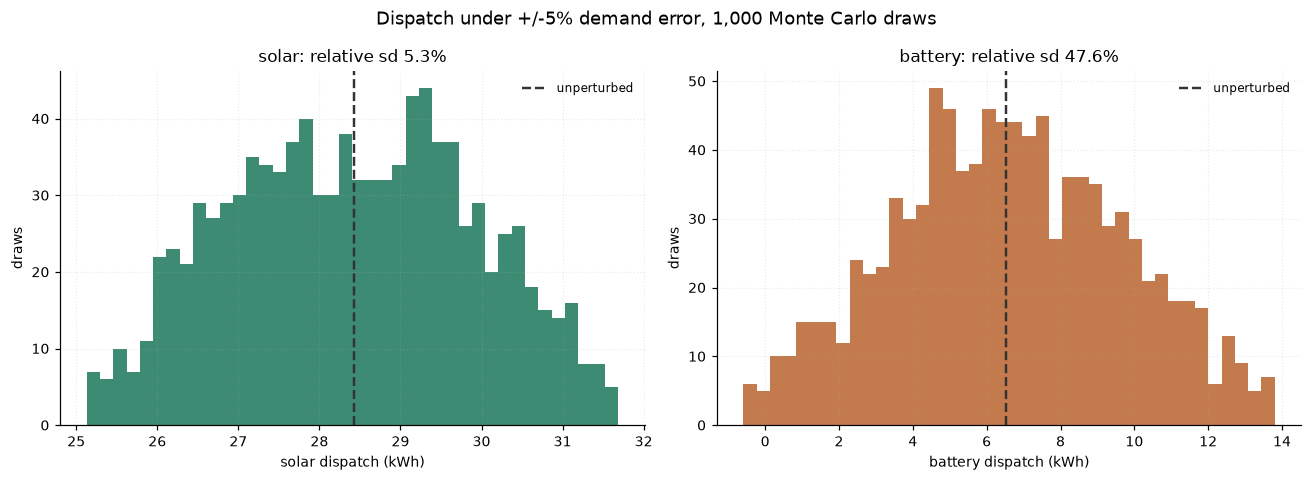

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, index in zip(axes, range(grid.order)):
    source = grid.sources[index]
    ax.hist(solutions[index], bins=40, color=PALETTE[index], alpha=0.8)
    ax.axvline(sensitivity["baseline"][index], color="0.2", lw=1.6, ls="--",
               label="unperturbed")
    ax.set_xlabel(f"{source} dispatch (kWh)")
    ax.set_ylabel("draws")
    ax.set_title(f"{source}: relative sd "
                 f"{summary.loc[source, 'relative sd']:.1%}")
    ax.legend(fontsize=8)
fig.suptitle("Dispatch under +/-5% demand error, 1,000 Monte Carlo draws",
             fontsize=12)
fig.tight_layout()
print("saved:", save(fig, "mp2_sensitivity.png").name)
plt.show()

The asymmetry is the point. Solar moves by a few percent; the battery, which
is a small difference between two larger numbers, moves by far more in
relative terms. The condition number describes the *system*, but the risk
falls almost entirely on one component of the answer.

## Findings & Limitations

**Findings.** The system is well posed and well conditioned: $\det A = -5$
and $\kappa \approx 5.83$, so a unique dispatch exists for every demand pair
and a 1% metering error cannot become more than about 6% in the answer. The
Monte Carlo check confirmed this empirically, with the worst amplification
over 1,000 draws landing just under $\kappa$. Solving all 30 days in one
vectorised call runs about 5x faster than looping, almost entirely because it
pays SciPy's per-call overhead once instead of thirty times, not because the
arithmetic is cheaper. Four of the 30 days were
physically infeasible -- all of them days where $D_2 > \tfrac{4}{3}D_1$,
which drives the battery allocation negative -- and were repaired by clipping
to zero, leaving about 18 kWh of demand unserved across the month. The
battery is dramatically the more volatile source: its CV of 0.69 against
solar's 0.10 reflects that it is the swing producer absorbing whatever the
fixed load ratio leaves over. Because it is also three times dearer per kWh,
it drives both the level and the variability of the bill, which runs at about
UGX 7,300 a day, or roughly UGX 220,000 a month. Adding a diesel generator
under an evening-load constraint keeps the system well conditioned
($\det = -20$).

**Limitations.** The demand data are synthetic, so the infeasible-day count
is a property of the generator's noise rather than of Kasese. The model is a
pure equality system with no capacity limits: nothing stops it dispatching
more solar at night than panels could physically produce, and a real planner
would need inequality constraints and a storage state rather than a square
solve. The clipping repair is deliberately crude -- it restores feasibility
but makes no attempt to minimise the shortfall, which is what a non-negative
least-squares or a bounded solve would do, and the unmet energy reported here
should be read as an upper bound on what a smarter repair would leave. The
tariffs are flat and illustrative, ignoring battery degradation, which is the
dominant real cost of cycling storage hard. Finally, the condition number
bounds *relative* error in a norm, so it says nothing about which component
absorbs it; here the battery takes almost all of it, and that only became
visible by simulating.